<a href="https://colab.research.google.com/github/HoangThiThi199/ASM-Machine-Translation/blob/main/demo_transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Giới Thiệu Transformer
Sự nổi tiếng của mô hình Transformer thì không cần phải bàn cãi, vì nó chính là nền tảng của rất nhiều mô hình khác mà nổi tiếng nhất là BERT (Bidirectional Encoder Representations from Transformers) một mô hình dùng để học biểu diễn của các từ tốt nhất hiện tại và đã tạo ra một bước ngoặc lớn cho động đồng NLP trong năm 2019. Và chính Google cũng đã áp dụng BERT trong cỗ máy tìm kiếm của họ. Để hiểu BERT, các bạn cần phải nắm rõ về mô hình Transformer.

![alt text](https://pbcquoc.github.io/images/transformer/bert.jpg)

Ý tưởng chủ đạo của Transformer vẫn là áp dụng cơ thể Attention, những ở mức phức tạp hơn và thật sự là thú vị hơn so với cách được đề xuất trước đó trong một bài báo của tác giả Lương Minh Thắng, một người Việt rất nổi tiếng trong cộng đồng deep learning.

## Tổng Quan Mô Hình
Để cho dễ cảm nhận được cách mà mô hình hoạt động, mình sẽ trình bày trước toàn bộ kiến trúc mô hình ở mức high-level và sau đó sẽ đi chi tiết từng phần nhỏ cũng như công thức toán của nó.

Giống như những mô hình dịch máy khác, kiến trúc tổng quan của mô hình transformer bao gồm 2 phần lớn là encoder và decoder. Encoder dùng để học vector biểu của câu với mong muốn rằng vector này mang thông tin hoàn hảo của câu đó. Decoder thực hiện chức năng chuyển vector biểu diễn kia thành ngôn ngữ đích.

Trong ví dụ ở dưới, encoder của mô hình transformer nhận một câu tiếng việt, và encode thành một vector biểu diễn ngữ nghĩa của câu little sun, sau đó mô hình decoder nhận vector biểu diễn này, và dịch nó thành câu tiếng việt mặt trời bé nhỏ

![alt text](https://pbcquoc.github.io/images/transformer/overview.jpg)

Một trong những ưu điểm của transformer là mô hình này có khả năng xử lý song song cho các từ. Như các bạn thấy, Encoders của mô hình transfomer là một dạng feedforward neural nets, bao gồm nhiều encoder layer khác, mỗi encoder layer này xử lý đồng thời các từ. Trong khi đó, với mô hình LSTM, thì các từ phải được xử lý tuần tự. Ngoài ra, mô hình Transformer còn xử lý câu đầu vào theo 2 hướng mà không cần phải stack thêm một môt hình LSTM nữa như trong kiến trúc Bidirectional LSTM.

![alt text](https://pbcquoc.github.io/images/transformer/overview2.jpg)

Một cái nhìn vừa tổng quát và chi tiết sẽ giúp ích cho các bạn. Mình sẽ đi vào chi tiết một số phần cực kì quan trọng như sinusoidal position encoding, multi head attention của encoder, còn của decoder thì các bạn thấy được kiến trúc rất giống với của encoder, do đó mình sẽ chỉ đi nhanh qua mà thôi.

![](https://pbcquoc.github.io/images/transformer/overview3.jpg)

In [3]:
%pip -q install torchtext==0.6.0 pyvi dill pandas gdown spacy seaborn matplotlib

from torchtext import data
required_apis = ["Field", "TabularDataset", "Iterator", "batch", "Dataset", "Example"]
missing = [name for name in required_apis if not hasattr(data, name)]
if missing:
    raise RuntimeError(f"TorchText thiếu API: {missing}. Hãy kiểm tra lại phiên bản TorchText.")
print("Environment dependencies are ready.")


Environment dependencies are ready.


In [4]:
import os
import math
import copy
import time
import random
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


# Embedding Layer with Position Encoding
Trước khi đi vào mô hình encoder, chúng ta sẽ tìm hiểu cơ chế rất thú vị là Position Encoding dùng để đưa thông tin về vị trí của các từ vào mô hình transformer.

Đầu tiên, các từ được biểu diễn bằng một vector sử dụng một ma trận word embedding có số dòng bằng kích thước của tập từ vựng. Sau đó các từ trong câu được tìm kiếm trong ma trận này, và được nối nhau thành các dòng của một ma trận 2 chiều chứa ngữ nghĩa của từng từ riêng biệt. Nhưng như các bạn đã thấy, transformer xử lý các từ song song, do đó, với chỉ word embedding mô hình không thể nào biết được vị trí các từ. Như vậy, chúng ta cần một cơ chế nào đó để đưa thông tin vị trí các từ vào trong vector đầu vào. Đó là lúc positional encoding xuất hiện và giải quyết vấn đề của chúng ta. Tuy nhiên, trước khi giới thiệu cơ chế position encoding của tác giả, các bạn có thể giải quyết vấn đề băng một số cách naive như sau:

Biểu diễn vị trí các từ bằng chuỗi các số liên tục từ 0,1,2,3 …, n. Tuy nhiên, chúng ta gặp ngay vấn đề là khi chuỗi dài thì số này có thể khá lớn, và mô hình sẽ gặp khó khăn khi dự đoán những câu có chiều dài lớn hơn tất cả các câu có trong tập huấn luyện. Để giải quyết vấn đề này, các bạn có thể chuẩn hóa lại cho chuỗi số này nằm trong đoạn từ 0-1 bằng cách chia cho n nhưng mà chúng ta sẽ gặp vấn đề khác là khoảng cách giữ 2 từ liên tiếp sẽ phụ thuộc vào chiều dài của chuỗi, và trong một khoản cố định, chúng ta không hình dùng được khoản đó chứa bao nhiêu từ. Điều này có nghĩa là ý nghĩa của position encoding sẽ khác nhau tùy thuộc vào độ dài của câu đó.

In [5]:
class Embedder(nn.Module):
    def __init__(self, vocab_size, d_model):
        super().__init__()
        self.vocab_size = vocab_size
        self.d_model = d_model

        self.embed = nn.Embedding(vocab_size, d_model)

    def forward(self, x):
        return self.embed(x)

# Embedder(100, 512)(torch.LongTensor([1,2,3,4])).shape

# Phương pháp đề xuất sinusoidal position encoding
Phương pháp của tác giả đề xuất không gặp những hạn chế mà chúng ta vừa nêu. Vị trí của các từ được mã hóa bằng một vector có kích thước bằng word embedding và được cộng trực tiếp vào word embedding.

![](https://pbcquoc.github.io/images/transformer/embedding.jpg)

Cụ thể, tại vị trí chẵn, tác giả sử dụng hàm sin, và với vị trí lẽ tác giả sử dụng hàm cos để tính giá trị tại chiều đó.

![alt text](https://github.com/pbcquoc/pbcquoc.github.io/raw/master/images/transformer/pe_formula.png)

Trong hình dưới này, mình minh họa cho cách tính position encoding của tác giả. Giả sử chúng ta có word embedding có 6 chiều, thì position encoding cũng có tương ứng là 6 chiều. Mỗi dòng tương ứng với một từ. Giá trị của các vector tại mỗi vị trí được tính toán theo công thức ở hình dưới.

![](https://pbcquoc.github.io/images/transformer/pe.png)

Lúc này một số bạn sẽ thắc mắc tại sao với cách biểu diện vị trí như tác giả đề xuất lại có thể mã hóa thông tin vị trí của từ? Hãy tưởng tượng bạn có các số từ 0-15. Các bạn có thể thấy rằng bit ngoài cùng bên phải thay đổi nhanh nhất mỗi 1 số, và sau đó là bit bên phải thứ 2, thay đổi mỗi 2 số, tương tự cho các bit khác.

![](https://pbcquoc.github.io/images/transformer/pe_intuition.jpg)

Trong công thức của tác giả đề xuất, các bạn cũng thấy rằng, hàm sin và cos có dạng đồ thị tần số và tần số này giảm dần ở các chiều lớn dần. Các bạn xem hình dưới, ở chiều 0, giá trị thay đổi liên tục tương ứng với màu sắc thay đổi liên tục, và tần số thay đổi này giảm dần ở các chiều lớn hơn.

![](https://pbcquoc.github.io/images/transformer/pe_heatmap.png)

Nên chúng ta có thể cảm nhận được việc biểu diễn của tác giả khá tương tự như cách biểu diễn các số nguyên trong hệ nhị phân, cho nên chúng ta có thể biểu diễn được vị trí các từ theo cách như vậy.

Chúng ta cũng có thể xem ma trận khoảng cách của các vector biểu diễn vị trí như hình dưới. Rõ ràng, các vector biểu diễn thể hiện được tính chất khoảng cách giữ 2 từ. 2 từ cách càng xa nhau thì khoảng cách càng lớn hơn.

![](https://pbcquoc.github.io/images/transformer/pe_distance.png)

Ngoài ra, một tính chất của phương pháp tác giả đề xuất là nó cho phép mô hình dễ dàng học được mối quan hệ tương đối giữ các từ. Cụ thể, biểu diễn vị trí của từ t + offset có thể chuyển thành biểu diễn vị trí của từ t bằng một phép biến đổi tuyến tính dựa trên ma trận phép quay.

Để dễ hình dung phương pháp của tác giả đề xuất lại hoạt động tốt, các bạn có thể tưởng tượng, hàm sin, và cos, giống như là kim giây và kim phút trên đồng hồ. Với 2 kim này, chúng ta có thể biểu diễn được 3600 vị trí. Và đồng thời có thể hiểu được ngay tại sao biểu diễn của từ t + offset và từ t lại có thể dễ dàng chuyển đổi cho nhau.



In [6]:
class PositionalEncoder(nn.Module):
    """Sinusoidal positional encoding from the original Transformer paper."""
    def __init__(self, d_model, max_seq_length=200, dropout=0.1):
        super().__init__()
        self.d_model = d_model
        self.dropout = nn.Dropout(dropout)

        positions = torch.arange(max_seq_length, dtype=torch.float).unsqueeze(1)
        dimensions = torch.arange(0, d_model, 2, dtype=torch.float)
        div_term = torch.exp(dimensions * (-math.log(10000.0) / d_model))

        pe = torch.zeros(max_seq_length, d_model)
        pe[:, 0::2] = torch.sin(positions * div_term)
        # Handle both even and odd d_model safely.
        odd_width = pe[:, 1::2].shape[1]
        pe[:, 1::2] = torch.cos(positions * div_term[:odd_width])

        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        x = x * math.sqrt(self.d_model)
        seq_length = x.size(1)
        if seq_length > self.pe.size(1):
            raise ValueError(
                f"Sequence length {seq_length} exceeds positional encoding limit "
                f"{self.pe.size(1)}."
            )
        x = x + self.pe[:, :seq_length].to(dtype=x.dtype)
        return self.dropout(x)

# Encoder
Encoder của mô hình transformer có thể bao gồm nhiều encoder layer tượng tự nhau. Mỗi encoder layer của transformer lại bao gồm 2 thành phần chính là multi head attention và feedforward network, ngoài ra còn có cả skip connection và normalization layer.

Trong 2 thành phần chính này, các bạn sẽ hứng thú nhiều hơn về multi-head attention vì đó là một layer mới được giới thiệu trong bài báo này, và chính nó tạo nên sự khác biệt giữ mô hình LSTM và mô hình Transformer mà chúng ta đang tìm hiểu.
![alt text](https://pbcquoc.github.io/images/transformer/encoder.jpg)

Encoder đầu tiên sẽ nhận ma trận biểu diễn của các từ đã được cộng với thông tin vị trí thông qua positional encoding. Sau đó, ma trận này sẽ được xử lý bởi Multi Head Attention. Multi Head Attention thật chất là self-attention, nhưng mà để mô hình có thể có chú ý nhiều pattern khác nhau, tác giả đơn giản là sử dụng nhiều self-attention.

## Self Attention Layer
Self Attention cho phép mô hình khi mã hóa một từ có thể sử dụng thông tin của những từ liên quan tới nó. Ví dụ khi từ nó được mã hóa, nó sẽ chú ý vào các từ liên quan như là mặt trời. Cơ chế self attention này có ý nghĩa tương tự như cơ chế attention mình đã chia sẻ ở bài trước và những công thức toán học cũng tương ứng với nhau.

![alt text](https://pbcquoc.github.io/images/transformer/self_attention.jpg)

Bạn có thể tưởng tượng cơ chế self attention giống như cơ chế tìm kiếm. Với một từ cho trước, cơ chế này sẽ cho phép mô hình tìm kiếm trong cách từ còn lại, từ nào “giống” để sau đó thông tin sẽ được mã hóa dựa trên tất cả các từ trên.

Đầu tiên, với môi từ chúng ta cần tạo ra 3 vector: query, key, value vector bằng cách nhân ma trận biểu diễn các từ đầu vào với ma trận học tương ứng.

* query vector: vector dùng để chứa thông tin của từ được tìm kiếm, so sách. Giống như là câu query của google search.
* key vector: vector dùng để biểu diễn thông tin các từ được so sánh với từ cần tìm kiếm ở trên. Ví dụ, như các trang webs mà google sẽ so sánh với từ khóa mà bạn tìm kiếm.
* value vector: vector biểu diễn nội dung, ý nghĩa của các từ. Các bạn có thể tượng tượng, nó như là nội dung trang web được hiển thị cho người dùng sau khi tìm kiếm.
Để tính tương quan, chúng ta đơn giản chỉ cần tính tích vô hướng dựa các vector query và key. Sau đó dùng hàm softmax để chuẩn hóa chỉ số tương quan trong đoạn 0-1, và cuối cùng, tính trung bình cộng có trọng số giữa các vector values sử dụng chỉ số tương quan mới tính được. Quá dễ !!!

![](https://pbcquoc.github.io/images/transformer/self_attention_2.png)

Cụ thể hơn, quá trình tính toán attention vector có thể được tóm tắt làm 3 bước như sau:

* Bước 1: Tính ma trận query, key, value bằng cách khởi tạo 3 ma trận trọng số query, key, vector. Sau đó nhân input với các ma trận trọng số này để tạo thành 3 ma trận tương ứng.
* Bước 2: Tính attention weights. Nhân 2 ma trận key, query vừa được tính ở trên với nhau để với ý nghĩa là so sánh giữ câu query và key để học mối tương quan. Sau đó thì chuẩn hóa về đoạn [0-1] bằng hàm softmax. 1 có nghĩa là câu query giống với key, 0 có nghĩa là không giống.
* Bước 3: Tính output. Nhân attention weights với ma trận value. Điều này có nghĩa là chúng ta biểu diễn một từ bằng trung bình có trọng số (attention weights) của ma trận value.

![](https://pbcquoc.github.io/images/transformer/attention_vector.jpg)

## Multi Head Attention
Chúng ta muốn mô hình có thể học nhiều kiểu mối quan hệ giữ các từ với nhau. Với mỗi self-attention, chúng ta học được một kiểu pattern, do đó để có thể mở rộng khả năng này, chúng ta đơn giản là thêm nhiều self-attention. Tức là chúng ta cần nhiều ma trận query, key, value mà thôi. Giờ đây ma trận trọng số key, query, value sẽ có thêm 1 chiều depth nữa.

![](https://pbcquoc.github.io/images/transformer/multi_head_attention.jpg)

Multi head attention cho phép mô hình chú ý đến đồng thời những pattern dễ quan sát được như sau.

* Chú ý đến từ kế trước của một từ
* Chú ý đến từ kế sau của một từ
* Chú ý đến những từ liên quan của một từ

In [7]:
def attention(q, k, v, mask=None, dropout=None):
    """
    Scaled dot-product attention.
    q, k, v: [batch, heads, sequence, head_dim]
    mask: broadcastable to [batch, heads, query_length, key_length],
          with True/1 for positions that may be attended to.
    """
    d_k = q.size(-1)
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)

    if mask is not None:
        mask = mask.to(device=scores.device, dtype=torch.bool)
        if mask.dim() == 3:
            mask = mask.unsqueeze(1)
        scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)

    weights = F.softmax(scores, dim=-1)
    if dropout is not None:
        weights = dropout(weights)

    output = torch.matmul(weights, v)
    return output, weights

In [8]:
class MultiHeadAttention(nn.Module):
    def __init__(self, heads, d_model, dropout=0.1):
        super().__init__()
        assert d_model % heads == 0

        self.d_model = d_model
        self.d_k = d_model//heads
        self.h = heads
        self.attn = None

        # tạo ra 3 ma trận trọng số là q_linear, k_linear, v_linear như hình trên
        self.q_linear = nn.Linear(d_model, d_model)
        self.k_linear = nn.Linear(d_model, d_model)
        self.v_linear = nn.Linear(d_model, d_model)

        self.dropout = nn.Dropout(dropout)
        self.out = nn.Linear(d_model, d_model)

    def forward(self, q, k, v, mask=None):
        """
        q: batch_size x seq_length x d_model
        k: batch_size x seq_length x d_model
        v: batch_size x seq_length x d_model
        mask: batch_size x 1 x seq_length
        output: batch_size x seq_length x d_model
        """
        bs = q.size(0)
        # nhân ma trận trọng số q_linear, k_linear, v_linear với dữ liệu đầu vào q, k, v
        # ở bước encode các bạn lưu ý rằng q, k, v chỉ là một (xem hình trên)
        q = self.q_linear(q).view(bs, -1, self.h, self.d_k)
        k = self.k_linear(k).view(bs, -1, self.h, self.d_k)
        v = self.v_linear(v).view(bs, -1, self.h, self.d_k)

        q = q.transpose(1, 2)
        k = k.transpose(1, 2)
        v = v.transpose(1, 2)

        # tính attention score
        scores, self.attn = attention(q, k, v, mask, self.dropout)

        concat = scores.transpose(1, 2).contiguous().view(bs, -1, self.d_model)

        output = self.out(concat)
        return output

# MultiHeadAttention(8, 512)(torch.rand(32, 30, 512), torch.rand(32, 30, 512), torch.rand(32, 30, 512)).shape

# Residuals Connection và Normalization Layer

Trong kiến trúc của mô hình transformer, residuals connection và mormalization layer được sử dụng mọi nơi, giống như tinh thần của nó. 2 kỹ thuật giúp cho mô hình huấn luyện nhanh hội tụ hơn và trách mất mát thông tin trong quá trình huấn luyện mô hình, ví dụ như là thông tin của vị trí các từ được mã hóa.



In [9]:
class Norm(nn.Module):
    """Layer normalization."""
    def __init__(self, d_model, eps=1e-6):
        super().__init__()
        self.alpha = nn.Parameter(torch.ones(d_model))
        self.bias = nn.Parameter(torch.zeros(d_model))
        self.eps = eps

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        variance = x.var(dim=-1, unbiased=False, keepdim=True)
        return self.alpha * (x - mean) / torch.sqrt(variance + self.eps) + self.bias

In [10]:
class FeedForward(nn.Module):
    """ Trong kiến trúc của chúng ta có tầng linear
    """
    def __init__(self, d_model, d_ff=2048, dropout = 0.1):
        super().__init__()

        # We set d_ff as a default to 2048
        self.linear_1 = nn.Linear(d_model, d_ff)
        self.dropout = nn.Dropout(dropout)
        self.linear_2 = nn.Linear(d_ff, d_model)

    def forward(self, x):
        x = self.dropout(F.relu(self.linear_1(x)))
        x = self.linear_2(x)
        return x

In [11]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model, heads, dropout=0.1):
        super().__init__()
        self.norm_1 = Norm(d_model)
        self.norm_2 = Norm(d_model)
        self.attn = MultiHeadAttention(heads, d_model, dropout=dropout)
        self.ff = FeedForward(d_model, dropout=dropout)
        self.dropout_1 = nn.Dropout(dropout)
        self.dropout_2 = nn.Dropout(dropout)

    def forward(self, x, mask):
        """
        x: batch_size x seq_length x d_model
        mask: batch_size x 1 x seq_length
        output: batch_size x seq_length x d_model
        """


        x2 = self.norm_1(x)
        # tính attention value, các bạn để ý q, k, v là giống nhau
        x = x + self.dropout_1(self.attn(x2,x2,x2,mask))
        x2 = self.norm_2(x)
        x = x + self.dropout_2(self.ff(x2))
        return x

# EncoderLayer(512, 8)(torch.rand(32, 30, 512), torch.rand(32 , 1, 30)).shape

# Decoder
Decoder thực hiện chức năng giải mã vector của câu nguồn thành câu đích, do đó decoder sẽ nhận thông tin từ encoder là 2 vector key và value. Kiến trúc của decoder rất giống với encoder, ngoại trừ có thêm một multi head attention nằm ở giữ dùng để học mối liên quan giữ từ đang được dịch với các từ được ở câu nguồn.

![alt text](https://pbcquoc.github.io/images/transformer/decoder.jpg)

## Masked Multi Head Attention
Masked Multi Head Attention tất nhiên là multi head attention mà chúng ta đã nói đến ở trên, có chức năng dùng đề encode các từ câu câu đích trong quá trình dịch, tuy nhiên, lúc cài đặt chúng ta cần lưu ý rằng phải che đi các từ ở tương lai chưa được mô hình dịch đến, để làm việc này thì đơn giản là chúng ta chỉ cần nhân với một vector chứa các giá trị 0,1.

Trong decoder còn có một multi head attention khác có chức năng chú ý các từ ở mô hình encoder, layer này nhận vector key và value từ mô hình encoder, và output từ layer phía dưới. Đơn giản bởi vì chúng ta muốn so sánh sự tương quan giữ từ đang được dịch vời các từ nguồn.

In [12]:
class DecoderLayer(nn.Module):
    def __init__(self, d_model, heads, dropout=0.1):
        super().__init__()
        self.norm_1 = Norm(d_model)
        self.norm_2 = Norm(d_model)
        self.norm_3 = Norm(d_model)

        self.dropout_1 = nn.Dropout(dropout)
        self.dropout_2 = nn.Dropout(dropout)
        self.dropout_3 = nn.Dropout(dropout)

        self.attn_1 = MultiHeadAttention(heads, d_model, dropout=dropout)
        self.attn_2 = MultiHeadAttention(heads, d_model, dropout=dropout)
        self.ff = FeedForward(d_model, dropout=dropout)

    def forward(self, x, e_outputs, src_mask, trg_mask):
        """
        x: batch_size x seq_length x d_model
        e_outputs: batch_size x seq_length x d_model
        src_mask: batch_size x 1 x seq_length
        trg_mask: batch_size x 1 x seq_length
        """
        # Các bạn xem hình trên, kiến trúc mình vẽ với code ở chỗ này tương đương nhau.
        x2 = self.norm_1(x)
        # multihead attention thứ nhất, chú ý các từ ở target
        x = x + self.dropout_1(self.attn_1(x2, x2, x2, trg_mask))
        x2 = self.norm_2(x)
        # masked mulithead attention thứ 2. k, v là giá trị output của mô hình encoder
        x = x + self.dropout_2(self.attn_2(x2, e_outputs, e_outputs, src_mask))
        x2 = self.norm_3(x)
        x = x + self.dropout_3(self.ff(x2))
        return x

# DecoderLayer(512, 8)(torch.rand(32, 30, 512), torch.rand(32, 30, 512), torch.rand(32, 1, 30), torch.rand(32, 1, 30)).shape

# Cài đặt Encoder
bao gồm N encoder layer

In [13]:
import copy

def get_clones(module, N):
    return nn.ModuleList([copy.deepcopy(module) for i in range(N)])

class Encoder(nn.Module):
    """Một encoder có nhiều encoder layer nhé !!!
    """
    def __init__(self, vocab_size, d_model, N, heads, dropout):
        super().__init__()
        self.N = N
        self.embed = Embedder(vocab_size, d_model)
        self.pe = PositionalEncoder(d_model, dropout=dropout)
        self.layers = get_clones(EncoderLayer(d_model, heads, dropout), N)
        self.norm = Norm(d_model)

    def forward(self, src, mask):
        """
        src: batch_size x seq_length
        mask: batch_size x 1 x seq_length
        output: batch_size x seq_length x d_model
        """
        x = self.embed(src)
        x = self.pe(x)
        for i in range(self.N):
            x = self.layers[i](x, mask)
        return self.norm(x)

# Encoder(232, 512,6,8,0.1)(torch.LongTensor(32, 30).random_(0, 10), torch.rand(32, 1, 30)).shape

# Cài đặt Decoder
bao gồm N decoder layers

In [14]:
class Decoder(nn.Module):
    """Một decoder có nhiều decoder layer nhé !!!
    """
    def __init__(self, vocab_size, d_model, N, heads, dropout):
        super().__init__()
        self.N = N
        self.embed = Embedder(vocab_size, d_model)
        self.pe = PositionalEncoder(d_model, dropout=dropout)
        self.layers = get_clones(DecoderLayer(d_model, heads, dropout), N)
        self.norm = Norm(d_model)
    def forward(self, trg, e_outputs, src_mask, trg_mask):
        """
        trg: batch_size x seq_length
        e_outputs: batch_size x seq_length x d_model
        src_mask: batch_size x 1 x seq_length
        trg_mask: batch_size x 1 x seq_length
        output: batch_size x seq_length x d_model
        """
        x = self.embed(trg)
        x = self.pe(x)
        for i in range(self.N):
            x = self.layers[i](x, e_outputs, src_mask, trg_mask)
        return self.norm(x)

# Decoder(232, 512, 6, 8, 0.1)(torch.LongTensor(32, 30).random_(0, 10), torch.rand(32, 30, 512), torch.rand(32, 1, 30), torch.rand(32, 1, 30)).shape

# Cài đặt Transformer
bao gồm encoder và decoder

In [56]:
class Transformer(nn.Module):
    """ Cuối cùng ghép chúng lại với nhau để được mô hình transformer hoàn chỉnh
    """
    def __init__(self, src_vocab, trg_vocab, d_model, N, heads, dropout):
        super().__init__()
        self.encoder = Encoder(src_vocab, d_model, N, heads, dropout)
        self.decoder = Decoder(trg_vocab, d_model, N, heads, dropout)
        self.out = nn.Linear(d_model, trg_vocab)
    def forward(self, src, trg, src_mask, trg_mask):
        """
        src: batch_size x seq_length
        trg: batch_size x seq_length
        src_mask: batch_size x 1 x seq_length
        trg_mask batch_size x 1 x seq_length
        output: batch_size x seq_length x vocab_size
        """
        e_outputs = self.encoder(src, src_mask)

        d_output = self.decoder(trg, e_outputs, src_mask, trg_mask)
        output = self.out(d_output)
        return output

# Transformer(232, 232, 512, 6, 8, 0.1)(torch.LongTensor(32, 30).random_(0, 10), torch.LongTensor(32, 30).random_(0, 10),torch.rand(32, 1, 30),torch.rand(32, 1, 30)).shape

Chúng ta sử dụng torchtext để load dữ liệu, giúp giảm thời gian và hiệu quả

In [57]:
from torchtext import data

class MyIterator(data.Iterator):
    """Length-aware iterator that groups similarly sized examples."""
    def create_batches(self):
        if self.train:
            def pool(dataset, random_shuffler):
                for pooled in data.batch(dataset, self.batch_size * 100):
                    batches = data.batch(
                        sorted(pooled, key=self.sort_key),
                        self.batch_size,
                        self.batch_size_fn
                    )
                    for batch in random_shuffler(list(batches)):
                        yield batch
            self.batches = pool(self.data(), self.random_shuffler)
        else:
            self.batches = []
            for batch in data.batch(self.data(), self.batch_size, self.batch_size_fn):
                self.batches.append(sorted(batch, key=self.sort_key))

max_src_in_batch = 0
max_tgt_in_batch = 0

def batch_size_fn(new, count, sofar):
    """Batch by approximate token count rather than sentence count."""
    global max_src_in_batch, max_tgt_in_batch
    if count == 1:
        max_src_in_batch = 0
        max_tgt_in_batch = 0
    max_src_in_batch = max(max_src_in_batch, len(new.src))
    max_tgt_in_batch = max(max_tgt_in_batch, len(new.trg))
    src_elements = count * max_src_in_batch
    tgt_elements = count * max_tgt_in_batch
    return max(src_elements, tgt_elements)

In [58]:
def nopeak_mask(size, device):
    """Boolean causal mask: decoder position i cannot see positions > i."""
    return torch.tril(
        torch.ones((1, size, size), dtype=torch.bool, device=device)
    )

def create_masks(src, trg, src_pad, trg_pad, device):
    src_mask = (src != src_pad).unsqueeze(1)

    if trg is not None:
        trg_padding_mask = (trg != trg_pad).unsqueeze(1)
        causal_mask = nopeak_mask(trg.size(1), device)
        trg_mask = trg_padding_mask & causal_mask
    else:
        trg_mask = None

    return src_mask, trg_mask

In [59]:
from nltk.corpus import wordnet
import re

def get_synonym(word, SRC):
    syns = wordnet.synsets(word)
    for s in syns:
        for l in s.lemmas():
            if SRC.vocab.stoi[l.name()] != 0:
                return SRC.vocab.stoi[l.name()]

    return 0

def multiple_replace(replacements, text):
    """Apply punctuation spacing fixes to a decoded sentence."""
    if not replacements:
        return text
    pattern = re.compile("|".join(map(re.escape, replacements.keys())))
    return pattern.sub(lambda match: replacements[match.group(0)], text)

In [60]:
def init_vars(src, model, SRC, TRG, device, k, max_len):
    """Initialize beam-search hypotheses from the encoder output."""
    device = torch.device(device)
    sos_id = TRG.vocab.stoi["<sos>"]
    src_mask = (src != SRC.vocab.stoi["<pad>"]).unsqueeze(1)

    with torch.no_grad():
        encoder_output = model.encoder(src, src_mask)
        decoder_input = torch.tensor([[sos_id]], dtype=torch.long, device=device)
        trg_mask = nopeak_mask(1, device)
        logits = model.out(
            model.decoder(decoder_input, encoder_output, src_mask, trg_mask)
        )
        logits[:, :, TRG.vocab.stoi["<pad>"]] = torch.finfo(logits.dtype).min
        logits[:, :, sos_id] = torch.finfo(logits.dtype).min
        probabilities = F.softmax(logits[:, -1, :], dim=-1)
        k = min(k, probabilities.size(-1))
        top_probs, top_indices = probabilities.topk(k, dim=-1)

    outputs = torch.zeros((k, max_len), dtype=torch.long, device=device)
    outputs[:, 0] = sos_id
    outputs[:, 1] = top_indices[0]

    expanded_encoder = encoder_output.expand(k, -1, -1).contiguous()
    log_scores = torch.log(top_probs.clamp_min(1e-12))
    return outputs, expanded_encoder, log_scores


def k_best_outputs(outputs, logits, log_scores, position, k):
    """Expand and retain the k highest-scoring beam hypotheses."""
    probabilities = F.softmax(logits[:, -1, :], dim=-1)
    top_probs, top_indices = probabilities.topk(k, dim=-1)

    candidate_scores = (
        torch.log(top_probs.clamp_min(1e-12)) + log_scores.view(k, 1)
    )
    best_scores, best_flat_indices = candidate_scores.reshape(-1).topk(k)

    parent_rows = torch.div(best_flat_indices, k, rounding_mode="floor")
    token_cols = best_flat_indices.remainder(k)

    previous_outputs = outputs.clone()
    outputs[:, :position] = previous_outputs[parent_rows, :position]
    outputs[:, position] = top_indices[parent_rows, token_cols]
    return outputs, best_scores.unsqueeze(0)


def beam_search(src, model, SRC, TRG, device, k, max_len):
    device = torch.device(device)
    model.eval()
    k = max(1, min(k, len(TRG.vocab)))

    with torch.no_grad():
        outputs, encoder_outputs, log_scores = init_vars(
            src, model, SRC, TRG, device, k, max_len
        )
        eos_id = TRG.vocab.stoi["<eos>"]
        src_mask = (src != SRC.vocab.stoi["<pad>"]).unsqueeze(1)

        for position in range(2, max_len):
            trg_mask = nopeak_mask(position, device)
            logits = model.out(
                model.decoder(
                    outputs[:, :position], encoder_outputs, src_mask, trg_mask
                )
            )
            logits[:, :, TRG.vocab.stoi["<pad>"]] = torch.finfo(logits.dtype).min
            logits[:, :, TRG.vocab.stoi["<sos>"]] = torch.finfo(logits.dtype).min
            outputs, log_scores = k_best_outputs(
                outputs, logits, log_scores, position, k
            )
            if (outputs == eos_id).any(dim=1).all():
                break

        # Prefer completed hypotheses and apply a mild length penalty.
        finished = outputs.eq(eos_id)
        lengths = torch.full((k,), max_len, dtype=torch.float, device=device)
        for beam_index in range(k):
            eos_positions = finished[beam_index].nonzero(as_tuple=False)
            if eos_positions.numel():
                lengths[beam_index] = eos_positions[0, 0].float()

        normalized_scores = log_scores.squeeze(0) / (lengths.clamp_min(1) ** 0.7)
        best_index = int(normalized_scores.argmax().item())
        best_sequence = outputs[best_index]

        eos_positions = (best_sequence == eos_id).nonzero(as_tuple=False)
        end_position = int(eos_positions[0, 0].item()) if eos_positions.numel() else max_len
        token_ids = best_sequence[1:end_position].tolist()

    return " ".join(TRG.vocab.itos[token_id] for token_id in token_ids)

In [61]:
def translate_sentence(sentence, model, SRC, TRG, device, k=3, max_len=160):
    """Translate one English sentence into Vietnamese using beam search."""
    model.eval()
    tokens = SRC.preprocess(sentence)
    if not tokens:
        return ""

    unk_id = SRC.vocab.stoi["<unk>"]
    indexed = [SRC.vocab.stoi.get(token, unk_id) for token in tokens]
    source_tensor = torch.tensor(indexed, dtype=torch.long, device=device).unsqueeze(0)

    translated = beam_search(
        source_tensor, model, SRC, TRG, device, k, max_len
    )
    return multiple_replace(
        {" ?": "?", " !": "!", " .": ".", "' ": "'", " ,": ","},
        translated
    )

In [62]:
import spacy
from pyvi import ViTokenizer

# A lightweight English tokenizer; no external spaCy model download is needed.
_EN_TOKENIZER = spacy.blank("en").tokenizer

class tokenize:
    """Language-specific tokenizer used by TorchText Field."""

    def __init__(self, lang):
        self.lang = lang.lower()
        if self.lang not in ("en", "vi"):
            raise ValueError(f"Unsupported language: {lang}")

    def tokenizer(self, sentence):
        # Keep punctuation: both tokenizers can split punctuation into tokens.
        sentence = re.sub(r"\\s+", " ", str(sentence)).strip().lower()
        if not sentence:
            return []

        if self.lang == "en":
            return [
                token.text for token in _EN_TOKENIZER(sentence)
                if token.text.strip()
            ]

        # PyVi joins Vietnamese multi-syllable words with underscores.
        return ViTokenizer.tokenize(sentence).split()


## Data loader
Sử dụng torchtext để load dữ liệu nhanh chóng

In [63]:
import os
import dill as pickle
import pandas as pd
from torchtext import data

def read_data(src_file, trg_file):

    with open(src_file, "r", encoding="utf-8") as f:
        src_lines = f.readlines()

    with open(trg_file, "r", encoding="utf-8") as f:
        trg_lines = f.readlines()

    # Check physical line alignment
    if len(src_lines) != len(trg_lines):
        raise ValueError(
            f"Raw files are not aligned: "
            f"{len(src_lines)} English lines vs "
            f"{len(trg_lines)} Vietnamese lines."
        )

    src_data = []
    trg_data = []

    dropped_pairs = 0

    # Preserve original line correspondence
    for src, trg in zip(src_lines, trg_lines):

        src = src.strip()
        trg = trg.strip()

        # Only retain complete parallel pairs
        if src and trg:
            src_data.append(src)
            trg_data.append(trg)
        else:
            dropped_pairs += 1

    print("Original pairs:", len(src_lines))
    print("Retained pairs:", len(src_data))
    print("Dropped incomplete pairs:", dropped_pairs)

    assert len(src_data) == len(trg_data)

    return src_data, trg_data

def create_fields(src_lang, trg_lang):
    print(f"Loading tokenizers: source={src_lang}, target={trg_lang}")
    src_tokenizer = tokenize(src_lang)
    trg_tokenizer = tokenize(trg_lang)

    SRC = data.Field(
        lower=True,
        tokenize=src_tokenizer.tokenizer,
        batch_first=False
    )
    TRG = data.Field(
        lower=True,
        tokenize=trg_tokenizer.tokenizer,
        init_token="<sos>",
        eos_token="<eos>",
        batch_first=False
    )
    return SRC, TRG


def create_dataset(
    src_data, trg_data, max_strlen, batchsize, device, SRC, TRG,
    istrain=True
):
    """Build a TorchText Dataset directly; avoids temporary CSV/header issues."""
    if len(src_data) != len(trg_data):
        raise ValueError("Source and target datasets must have equal lengths.")

    examples = []
    for source_line, target_line in zip(src_data, trg_data):
        if len(source_line.split()) <= max_strlen and len(target_line.split()) <= max_strlen:
            examples.append(
                data.Example.fromlist(
                    [source_line, target_line],
                    [("src", SRC), ("trg", TRG)]
                )
            )

    if not examples:
        raise ValueError("No sentence pairs remain after max_strlen filtering.")

    dataset = data.Dataset(examples, [("src", SRC), ("trg", TRG)])
    iterator = MyIterator(
        dataset,
        batch_size=batchsize,
        device=device,
        repeat=False,
        sort_key=lambda example: (len(example.src), len(example.trg)),
        batch_size_fn=batch_size_fn,
        train=istrain,
        shuffle=istrain,
        sort=False
    )

    if istrain:
        SRC.build_vocab(dataset, min_freq=1)
        TRG.build_vocab(dataset, min_freq=1)

    print(f"Created {'training' if istrain else 'validation'} dataset: {len(examples)} pairs")
    return iterator

In [64]:
def step(model, optimizer, batch, criterion):
    """One training update."""
    model.train()
    target_device = next(model.parameters()).device

    src = batch.src.transpose(0, 1).to(target_device)
    trg = batch.trg.transpose(0, 1).to(target_device)
    trg_input = trg[:, :-1]

    src_mask, trg_mask = create_masks(
        src, trg_input, src_pad, trg_pad, target_device
    )
    predictions = model(src, trg_input, src_mask, trg_mask)
    targets = trg[:, 1:].contiguous().view(-1)

    optimizer.zero_grad()
    loss = criterion(
        predictions.reshape(-1, predictions.size(-1)),
        targets
    )
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step_and_update_lr()
    return float(loss.detach().item())

In [65]:
def validiate(model, valid_iter, criterion):
    """Calculate mean validation loss without updating model parameters."""
    model.eval()
    target_device = next(model.parameters()).device
    losses = []

    with torch.no_grad():
        for batch in valid_iter:
            src = batch.src.transpose(0, 1).to(target_device)
            trg = batch.trg.transpose(0, 1).to(target_device)
            trg_input = trg[:, :-1]

            src_mask, trg_mask = create_masks(
                src, trg_input, src_pad, trg_pad, target_device
            )
            predictions = model(src, trg_input, src_mask, trg_mask)
            targets = trg[:, 1:].contiguous().view(-1)

            loss = criterion(
                predictions.reshape(-1, predictions.size(-1)),
                targets
            )
            losses.append(float(loss.item()))

    return float(np.mean(losses)) if losses else float("nan")

# Optimizer
Để huấn luyện mô hình transformer, các bạn vẫn sử dụng Adam, tuy nhiên, learning rate cần phải được điều chỉnh trong suốt quá trình học theo công thức sau

![alt text](https://raw.githubusercontent.com/pbcquoc/pbcquoc.github.io/master/images/transformer/optimizer.png)

![alt text](https://pbcquoc.github.io/images/transformer/opt.png)


In [66]:
class ScheduledOptim():
    '''A simple wrapper class for learning rate scheduling'''

    def __init__(self, optimizer, init_lr, d_model, n_warmup_steps):
        self._optimizer = optimizer
        self.init_lr = init_lr
        self.d_model = d_model
        self.n_warmup_steps = n_warmup_steps
        self.n_steps = 0


    def step_and_update_lr(self):
        "Step with the inner optimizer"
        self._update_learning_rate()
        self._optimizer.step()


    def zero_grad(self):
        "Zero out the gradients with the inner optimizer"
        self._optimizer.zero_grad()


    def _get_lr_scale(self):
        d_model = self.d_model
        n_steps, n_warmup_steps = self.n_steps, self.n_warmup_steps
        return (d_model ** -0.5) * min(n_steps ** (-0.5), n_steps * n_warmup_steps ** (-1.5))

    def state_dict(self):
        optimizer_state_dict = {
            'init_lr':self.init_lr,
            'd_model':self.d_model,
            'n_warmup_steps':self.n_warmup_steps,
            'n_steps':self.n_steps,
            '_optimizer':self._optimizer.state_dict(),
        }

        return optimizer_state_dict

    def load_state_dict(self, state_dict):
        self.init_lr = state_dict['init_lr']
        self.d_model = state_dict['d_model']
        self.n_warmup_steps = state_dict['n_warmup_steps']
        self.n_steps = state_dict['n_steps']

        self._optimizer.load_state_dict(state_dict['_optimizer'])

    def _update_learning_rate(self):
        ''' Learning rate scheduling per step '''

        self.n_steps += 1
        lr = self.init_lr * self._get_lr_scale()

        for param_group in self._optimizer.param_groups:
            param_group['lr'] = lr

# Label Smoothing
Với mô hình nhiều triệu tham số của transformer, thì việt overfit là chuyện dễ dàng xảy ra. Để hạn chế hiện tượng overfit, các bạn có thể sử dụng kỹ thuật label smoothing. Về cơ bản thì ý tưởng của kỹ thuật này khá đơn giản, chúng ta sẽ phạt mô hình khi nó quá tự tin vào việc dự đoán của mình. Thay vì mã hóa nhãn là một one-hot vector, các bạn sẽ thay đổi nhãn này một chút bằng cách phân bố một tí xác suất vào các trường hợp còn lại.

![alt text](https://pbcquoc.github.io/images/transformer/label_smoothing.jpg)

Giờ thì các bạn sẽ an tâm khi có thể để số epoch lớn mà không lo rằng mô hình sẽ overfit nặng nề.



In [67]:
class LabelSmoothingLoss(nn.Module):
    def __init__(self, classes, padding_idx, smoothing=0.0, dim=-1):
        super().__init__()
        if classes <= 2:
            raise ValueError("Vocabulary must contain more than two tokens.")
        self.confidence = 1.0 - smoothing
        self.smoothing = smoothing
        self.classes = classes
        self.dim = dim
        self.padding_idx = padding_idx

    def forward(self, pred, target):
        log_probs = F.log_softmax(pred, dim=self.dim)
        with torch.no_grad():
            true_dist = torch.full_like(
                log_probs, self.smoothing / (self.classes - 2)
            )
            true_dist.scatter_(1, target.unsqueeze(1), self.confidence)
            true_dist[:, self.padding_idx] = 0
            padding_rows = target.eq(self.padding_idx)
            true_dist[padding_rows] = 0

        return torch.sum(-true_dist * log_probs, dim=self.dim).mean()

In [68]:
from torchtext.data.metrics import bleu_score

def bleu(valid_src_data, valid_trg_data, model, SRC, TRG, device, k, max_strlen):
    if not valid_src_data:
        return 0.0

    predictions = [
        translate_sentence(sentence, model, SRC, TRG, device, k, max_strlen)
        for sentence in valid_src_data
    ]
    predicted_tokens = [TRG.preprocess(sentence) for sentence in predictions]
    reference_tokens = [
        [TRG.preprocess(reference)]
        for reference in valid_trg_data
    ]
    return bleu_score(predicted_tokens, reference_tokens)

In [69]:
opt = {
    "train_src_data": "./data/train.en",
    "train_trg_data": "./data/train.vi",
    "valid_src_data": "./data/tst2013.en",
    "valid_trg_data": "./data/tst2013.vi",
    "src_lang": "en",
    "trg_lang": "vi",
    "max_strlen": 160,
    "batchsize": 1500,
    "device": device,
    "d_model": 512,
    "n_layers": 6,
    "heads": 8,
    "dropout": 0.1,
    "lr": 0.0001,
    "epochs": 10,          # Increase to 30 for a longer experiment.
    "printevery": 200,
    "k": 3,
    "bleu_samples_per_epoch": 100
}
print("Configuration:", opt)

Configuration: {'train_src_data': './data/train.en', 'train_trg_data': './data/train.vi', 'valid_src_data': './data/tst2013.en', 'valid_trg_data': './data/tst2013.vi', 'src_lang': 'en', 'trg_lang': 'vi', 'max_strlen': 160, 'batchsize': 1500, 'device': device(type='cuda'), 'd_model': 512, 'n_layers': 6, 'heads': 8, 'dropout': 0.1, 'lr': 0.0001, 'epochs': 10, 'printevery': 200, 'k': 3, 'bleu_samples_per_epoch': 100}


In [70]:
# Download the English-Vietnamese IWSLT dataset archive.
import os
import gdown

os.makedirs("./data", exist_ok=True)
dataset_archive = "en_vi.zip"
if not os.path.exists(dataset_archive):
    file_id = "1Fuo_ALIFKlUvOPbK5rUA5OfAS2wKn_95"
    downloaded = gdown.download(
        id=file_id,
        output=dataset_archive,
        quiet=False
    )
    if not downloaded or not os.path.exists(dataset_archive):
        raise RuntimeError(
            "Dataset download failed. Check the Google Drive file availability "
            "or download en_vi.zip manually and upload it to this Colab session."
        )
else:
    print(f"{dataset_archive} already exists; skipping download.")

print("Dataset archive size:", os.path.getsize(dataset_archive), "bytes")

en_vi.zip already exists; skipping download.
Dataset archive size: 10109780 bytes


In [71]:
train_src_data, train_trg_data = read_data(
    opt["train_src_data"], opt["train_trg_data"]
)
valid_src_data, valid_trg_data = read_data(
    opt["valid_src_data"], opt["valid_trg_data"]
)

print("Training pairs:", len(train_src_data))
print("Validation pairs:", len(valid_src_data))
print("Sample English:", train_src_data[0])
print("Sample Vietnamese:", train_trg_data[0])

SRC, TRG = create_fields(opt["src_lang"], opt["trg_lang"])

train_iter = create_dataset(
    train_src_data, train_trg_data, opt["max_strlen"],
    opt["batchsize"], opt["device"], SRC, TRG, istrain=True
)
valid_iter = create_dataset(
    valid_src_data, valid_trg_data, opt["max_strlen"],
    opt["batchsize"], opt["device"], SRC, TRG, istrain=False
)

print("Source vocabulary:", len(SRC.vocab))
print("Target vocabulary:", len(TRG.vocab))

Original pairs: 133317
Retained pairs: 133166
Dropped incomplete pairs: 151
Original pairs: 1268
Retained pairs: 1268
Dropped incomplete pairs: 0
Training pairs: 133166
Validation pairs: 1268
Sample English: Rachel Pike : The science behind a climate headline
Sample Vietnamese: Khoa học đằng sau một tiêu đề về khí hậu
Loading tokenizers: source=en, target=vi
Created training dataset: 133089 pairs
Created validation dataset: 1268 pairs
Source vocabulary: 42662
Target vocabulary: 33762


In [72]:
# CHECK TRAINING BATCH

print("Training dataset size:", len(train_iter.dataset))
print("Validation dataset size:", len(valid_iter.dataset))

# Get one training batch
batch = next(iter(train_iter))

print("\nSource batch shape:", batch.src.shape)
print("Target batch shape:", batch.trg.shape)

print("\nSource vocabulary size:", len(SRC.vocab))
print("Target vocabulary size:", len(TRG.vocab))

print("\nEnglish vocabulary sample:")
print(SRC.vocab.itos[:20])

print("\nVietnamese vocabulary sample:")
print(TRG.vocab.itos[:20])

print("\nBatch check completed successfully!")

Training dataset size: 133089
Validation dataset size: 1268

Source batch shape: torch.Size([17, 88])
Target batch shape: torch.Size([17, 88])

Source vocabulary size: 42662
Target vocabulary size: 33762

English vocabulary sample:
['<unk>', '<pad>', ',', '.', 'the', '&', 'and', 'to', 'of', 'a', 'that', 'i', 'in', 'it', 'you', 'we', 'is', 'apos;s', 'this', ';']

Vietnamese vocabulary sample:
['<unk>', '<pad>', '<sos>', '<eos>', ',', '.', 'và', 'là', 'tôi', 'một', 'những', 'của', 'có', 'đó', 'bạn', 'không', 'trong', 'các', 'chúng_ta', 'người']

Batch check completed successfully!


In [74]:
# Extract the archive and locate the four parallel-corpus files.
import zipfile
import shutil
from pathlib import Path

with zipfile.ZipFile("en_vi.zip", "r") as archive:
    archive.extractall(".")

required_files = ["train.en", "train.vi", "tst2013.en", "tst2013.vi"]
for filename in required_files:
    matches = list(Path(".").rglob(filename))
    if not matches:
        raise FileNotFoundError(
            f"Could not find {filename} after extracting en_vi.zip. "
            "Inspect the archive contents and update the dataset paths."
        )
    source_path = matches[0]
    destination_path = Path("./data") / filename
    if source_path.resolve() != destination_path.resolve():
        shutil.copy2(source_path, destination_path)
    print(f"{filename}: {destination_path}")

train.en: data/train.en
train.vi: data/train.vi
tst2013.en: data/tst2013.en
tst2013.vi: data/tst2013.vi


In [75]:
src_pad = SRC.vocab.stoi["<pad>"]
trg_pad = TRG.vocab.stoi["<pad>"]
print("Source PAD id:", src_pad)
print("Target PAD id:", trg_pad)

Source PAD id: 1
Target PAD id: 1


In [76]:
model = Transformer(
    len(SRC.vocab),
    len(TRG.vocab),
    opt["d_model"],
    opt["n_layers"],
    opt["heads"],
    opt["dropout"]
)

for parameter in model.parameters():
    if parameter.dim() > 1:
        nn.init.xavier_uniform_(parameter)

model = model.to(opt["device"])
parameter_count = sum(parameter.numel() for parameter in model.parameters())
print(f"Model parameters: {parameter_count:,}")
print("Model device:", next(model.parameters()).device)

Model parameters: 100,589,538
Model device: cuda:0


In [77]:
optimizer = ScheduledOptim(
    torch.optim.Adam(
        model.parameters(),
        betas=(0.9, 0.98),
        eps=1e-9
    ),
    0.2,
    opt["d_model"],
    4000
)

criterion = LabelSmoothingLoss(
    len(TRG.vocab),
    padding_idx=trg_pad,
    smoothing=0.1
)

In [78]:
# Train the Transformer and save the best checkpoint by validation loss.
history = []
best_valid_loss = float("inf")
os.makedirs("./checkpoints", exist_ok=True)

for epoch in range(opt["epochs"]):
    model.train()
    epoch_train_losses = []
    start_time = time.time()

    for batch_index, batch in enumerate(train_iter, start=1):
        loss = step(model, optimizer, batch, criterion)
        epoch_train_losses.append(loss)

        if batch_index % opt["printevery"] == 0:
            print(
                f"Epoch {epoch + 1:02d}/{opt['epochs']} | "
                f"Batch {batch_index:05d} | "
                f"Train loss {np.mean(epoch_train_losses[-opt['printevery']:]):.4f}"
            )

    train_loss = float(np.mean(epoch_train_losses)) if epoch_train_losses else float("nan")
    valid_loss = validiate(model, valid_iter, criterion)

    sample_count = min(opt["bleu_samples_per_epoch"], len(valid_src_data))
    epoch_bleu = bleu(
        valid_src_data[:sample_count],
        valid_trg_data[:sample_count],
        model, SRC, TRG, opt["device"], opt["k"], opt["max_strlen"]
    ) if sample_count else 0.0

    elapsed = time.time() - start_time
    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "valid_loss": valid_loss,
        "bleu_sample": epoch_bleu,
        "seconds": elapsed
    })

    print(
        f"Epoch {epoch + 1:02d} complete | "
        f"train loss={train_loss:.4f} | "
        f"valid loss={valid_loss:.4f} | "
        f"sample BLEU={epoch_bleu:.4f} | "
        f"time={elapsed:.1f}s"
    )

    checkpoint = {
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "src_vocab": SRC.vocab,
        "trg_vocab": TRG.vocab,
        "options": opt,
        "history": history
    }
    torch.save(checkpoint, "./checkpoints/transformer_en_vi_latest.pt")

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        torch.save(checkpoint, "./checkpoints/transformer_en_vi_best.pt")
        print("Saved new best checkpoint.")

history_df = pd.DataFrame(history)
display(history_df)
history_df.to_csv("./checkpoints/training_history.csv", index=False)

Epoch 01/10 | Batch 00200 | Train loss 9.8548
Epoch 01/10 | Batch 00400 | Train loss 8.9892
Epoch 01/10 | Batch 00600 | Train loss 7.7112
Epoch 01/10 | Batch 00800 | Train loss 6.8471
Epoch 01/10 | Batch 01000 | Train loss 6.4960
Epoch 01/10 | Batch 01200 | Train loss 6.4582
Epoch 01/10 | Batch 01400 | Train loss 6.2099
Epoch 01/10 | Batch 01600 | Train loss 6.1484
Epoch 01/10 | Batch 01800 | Train loss 5.9908
Epoch 01/10 | Batch 02000 | Train loss 5.9218
Epoch 01 complete | train loss=7.0265 | valid loss=2.4027 | sample BLEU=0.0251 | time=574.4s
Saved new best checkpoint.
Epoch 02/10 | Batch 00200 | Train loss 5.7532
Epoch 02/10 | Batch 00400 | Train loss 5.6301
Epoch 02/10 | Batch 00600 | Train loss 5.5433
Epoch 02/10 | Batch 00800 | Train loss 5.4540
Epoch 02/10 | Batch 01000 | Train loss 5.3481
Epoch 02/10 | Batch 01200 | Train loss 5.2592
Epoch 02/10 | Batch 01400 | Train loss 5.1652
Epoch 02/10 | Batch 01600 | Train loss 5.0906
Epoch 02/10 | Batch 01800 | Train loss 4.9975
Epoch 

,epoch,train_loss,valid_loss,bleu_sample,seconds
0,1,7.026462,2.402675,0.025138,574.440606
1,2,5.302232,1.972360,0.083769,571.966498
2,3,4.481446,1.715834,0.136939,571.708838
3,4,4.008973,1.599354,0.172662,572.917109
4,5,3.751611,1.542840,0.188314,572.201787
5,6,3.583037,1.504424,0.200186,571.892680
6,7,3.460859,1.482271,0.217700,572.112154
7,8,3.365877,1.471232,0.206917,571.437762
8,9,3.286777,1.454647,0.210192,571.891670
9,10,3.220660,1.447556,0.213905,573.344581


In [81]:
# Final BLEU on the complete validation/test split.
final_bleu = bleu(
    valid_src_data, valid_trg_data,
    model, SRC, TRG, opt["device"], opt["k"], opt["max_strlen"]
)
print(f"Final BLEU: {final_bleu:.4f}")

Final BLEU: 0.2397


In [87]:
sentence='My family was not poor , and myself , I had never experienced hunger .'
trans_sent = translate_sentence(sentence, model, SRC, TRG, opt['device'], opt['k'], opt['max_strlen'])
trans_sent

'gia_đình tôi không nghèo, và chính bản_thân tôi, tôi chưa bao_giờ trải qua nạn đói.'

# Visualize

Nếu các bạn không muốn train tốn thời gian thì có thể sử dụng uncomment để download model mình đã train nhé.

In [88]:
import seaborn
import matplotlib.pyplot as plt

def draw(data, x, y, ax):
    seaborn.heatmap(data,
                    xticklabels=x, square=True, yticklabels=y, vmin=0.0, vmax=1.0,
                    cbar=False, ax=ax, annot=False)

# Visualize Encoder
Dùng heatmap để visualize giá trị attention sẽ cho chúng ta biết khi encode một câu mô hình chú ý từ gì ở lân cận

Encoder Layer 2


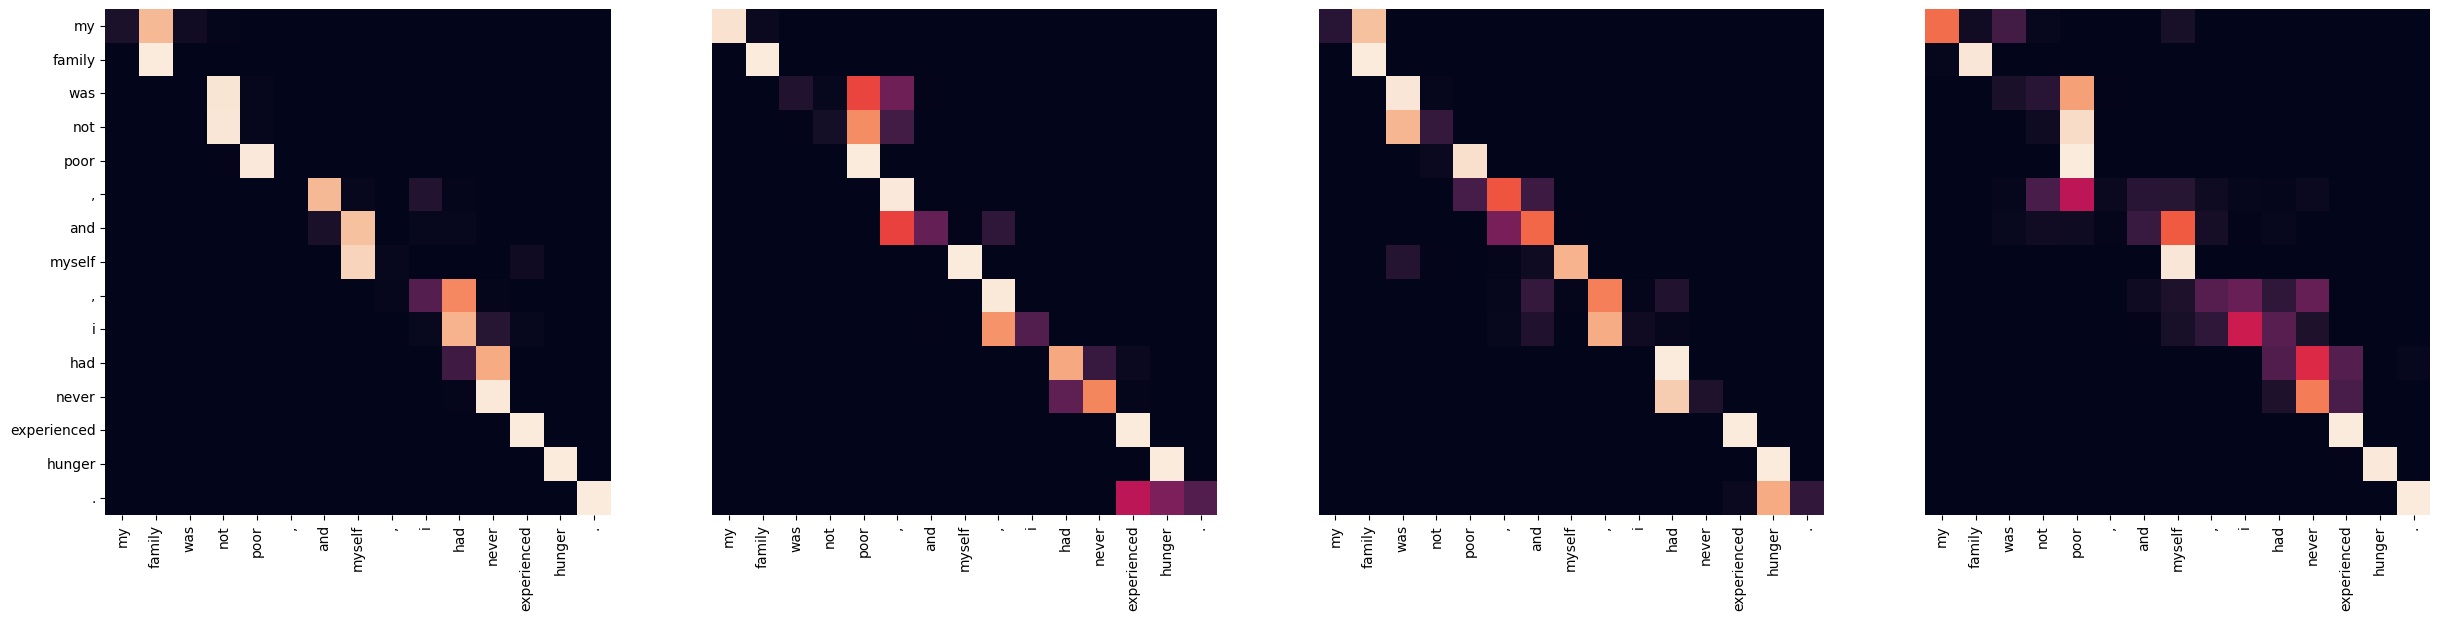

Encoder Layer 4


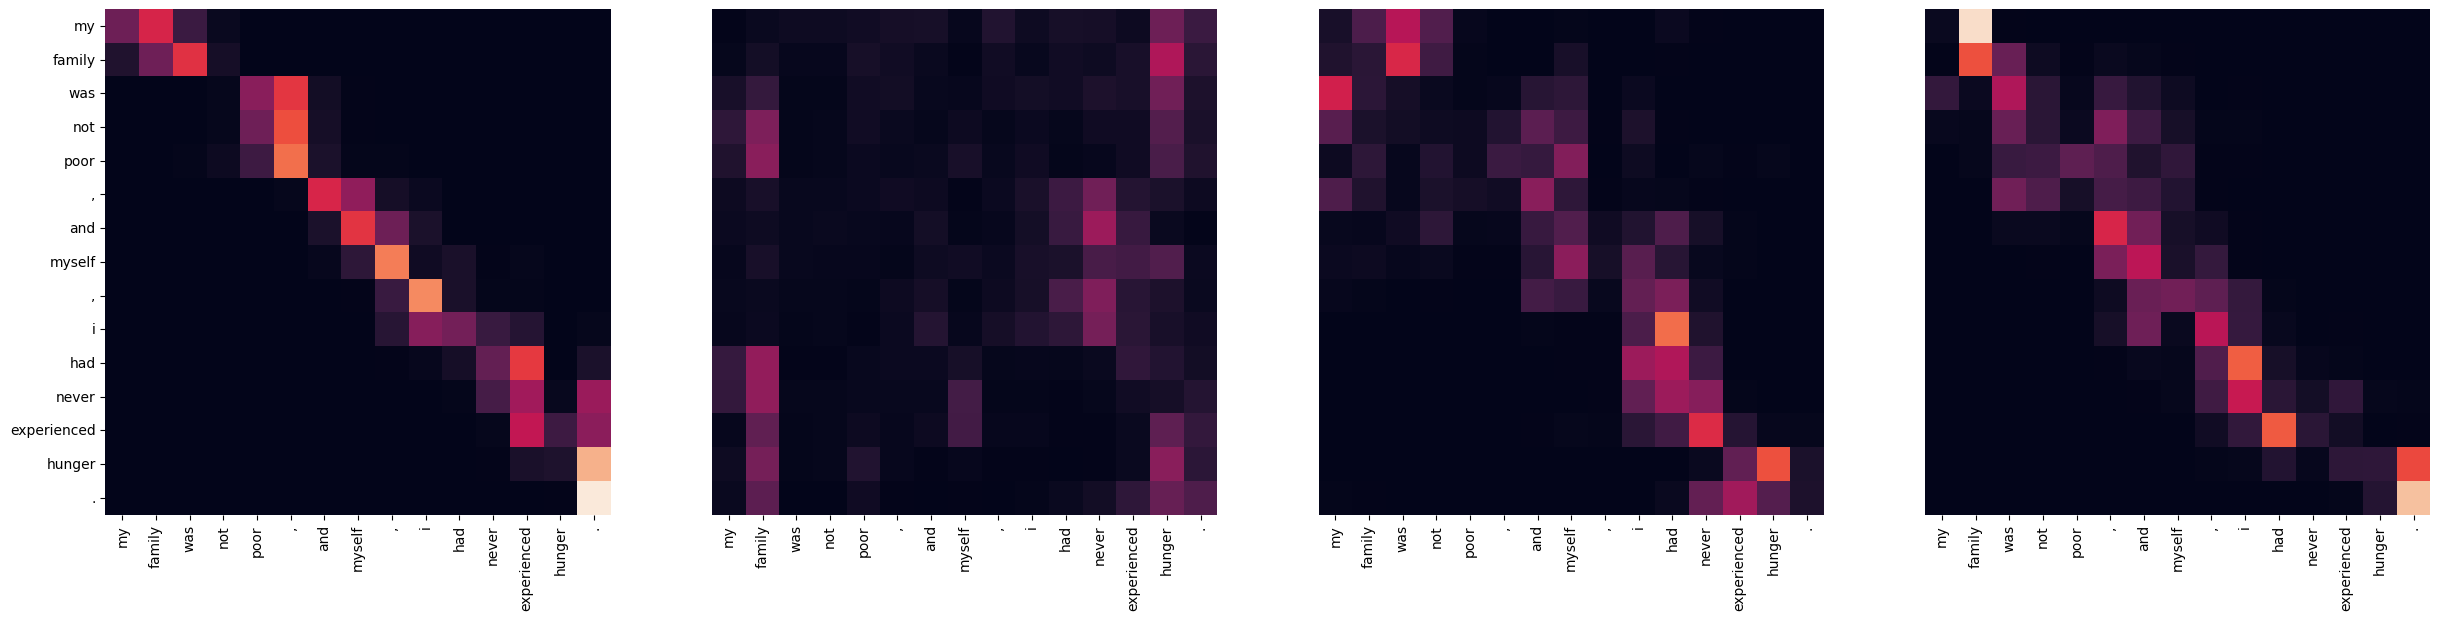

Encoder Layer 6


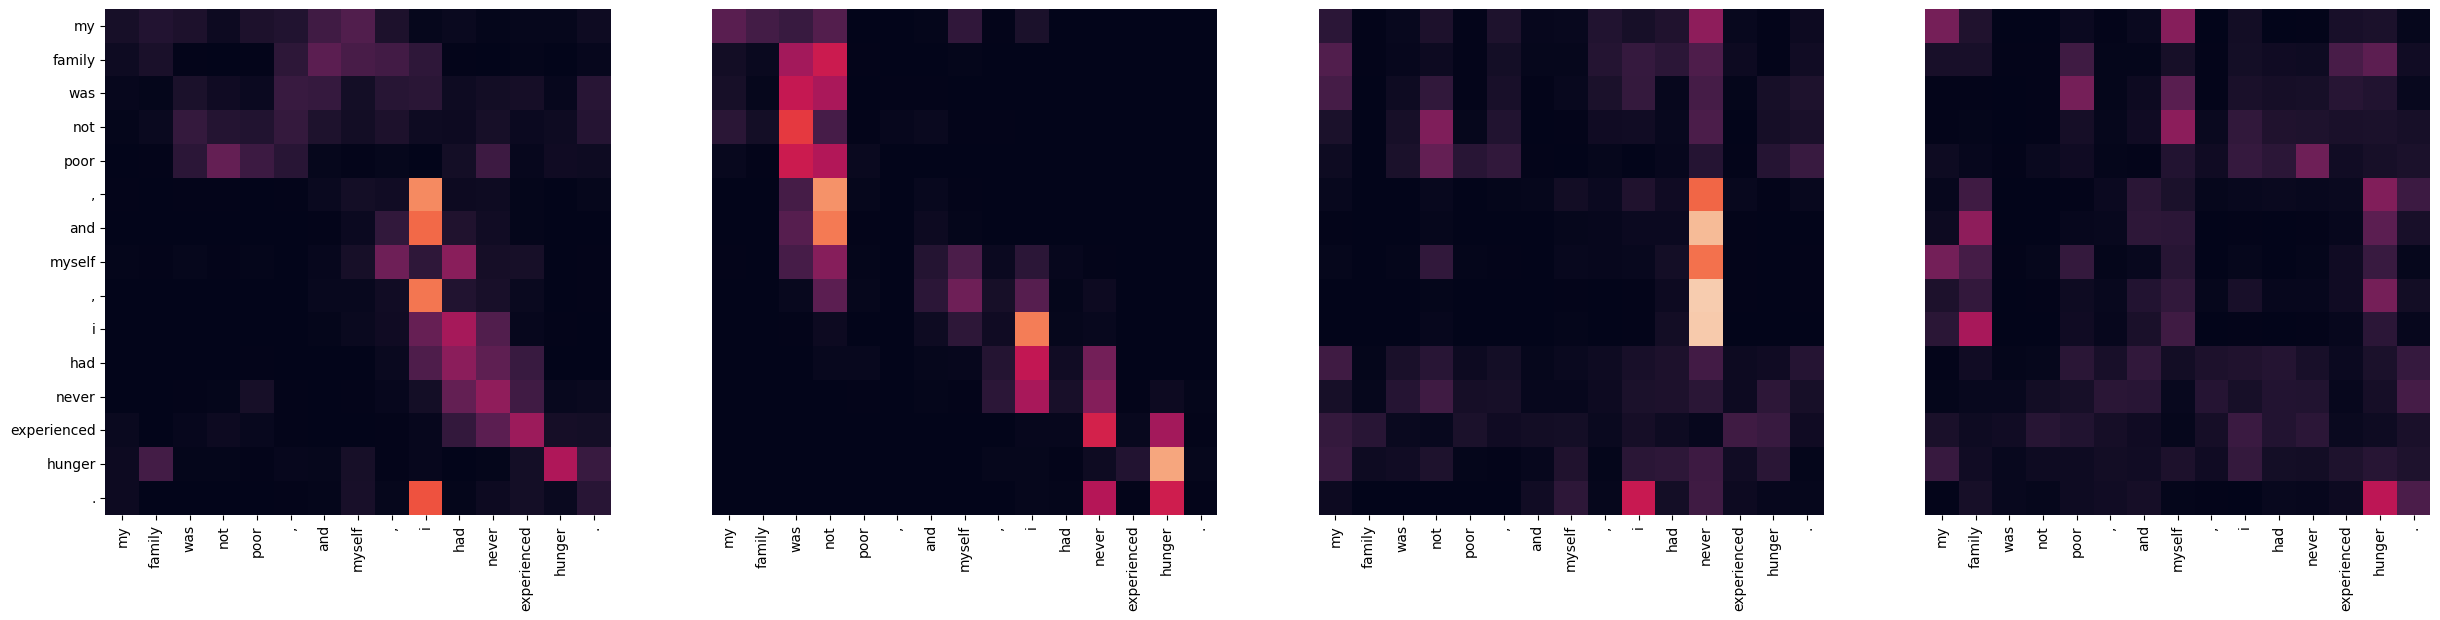

In [90]:
sent = SRC.preprocess(sentence)

for layer in range(1, 6, 2):
    fig, axs = plt.subplots(1,4, figsize=(30, 15))
    print("Encoder Layer", layer+1)
    for h in range(4):
        draw(model.encoder.layers[layer].attn.attn[0, h].data.cpu(),
            sent, sent if h ==0 else [], ax=axs[h])
    plt.show()

# Visualize Decoder
Ở decoder, các bạn có 2 loại visualization
* self attention: giá trị attention khi mô hình decoder mã hóa câu đích lúc dịch
* src attention: giá trị attention khi mô hình decoder sử dụng câu src

Decoder Self Layer 2


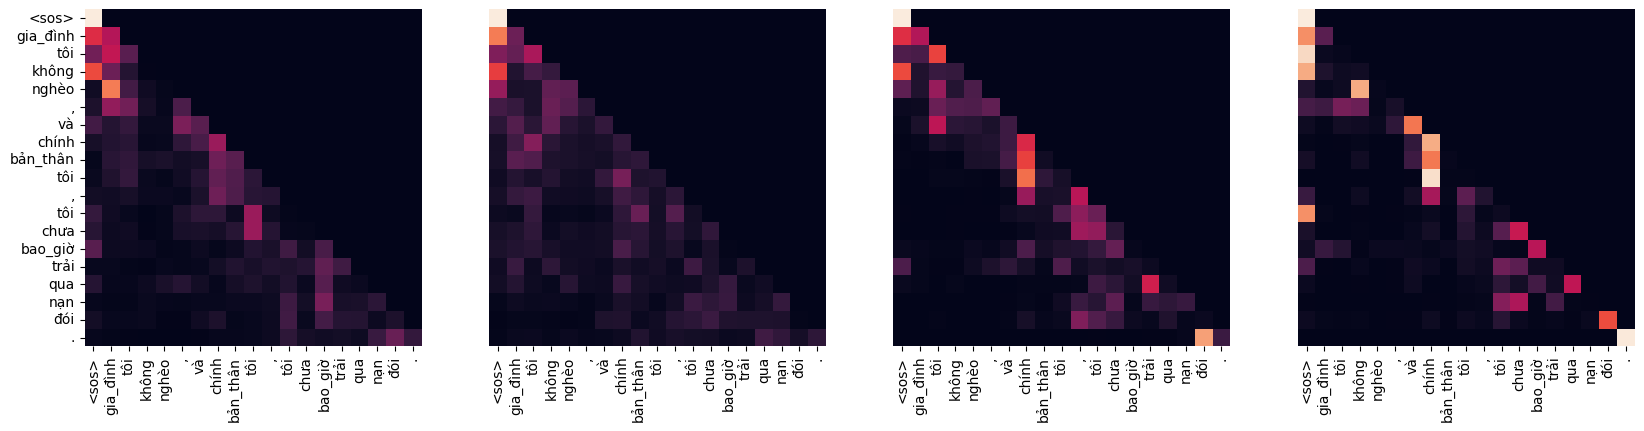

Decoder Src Layer 2


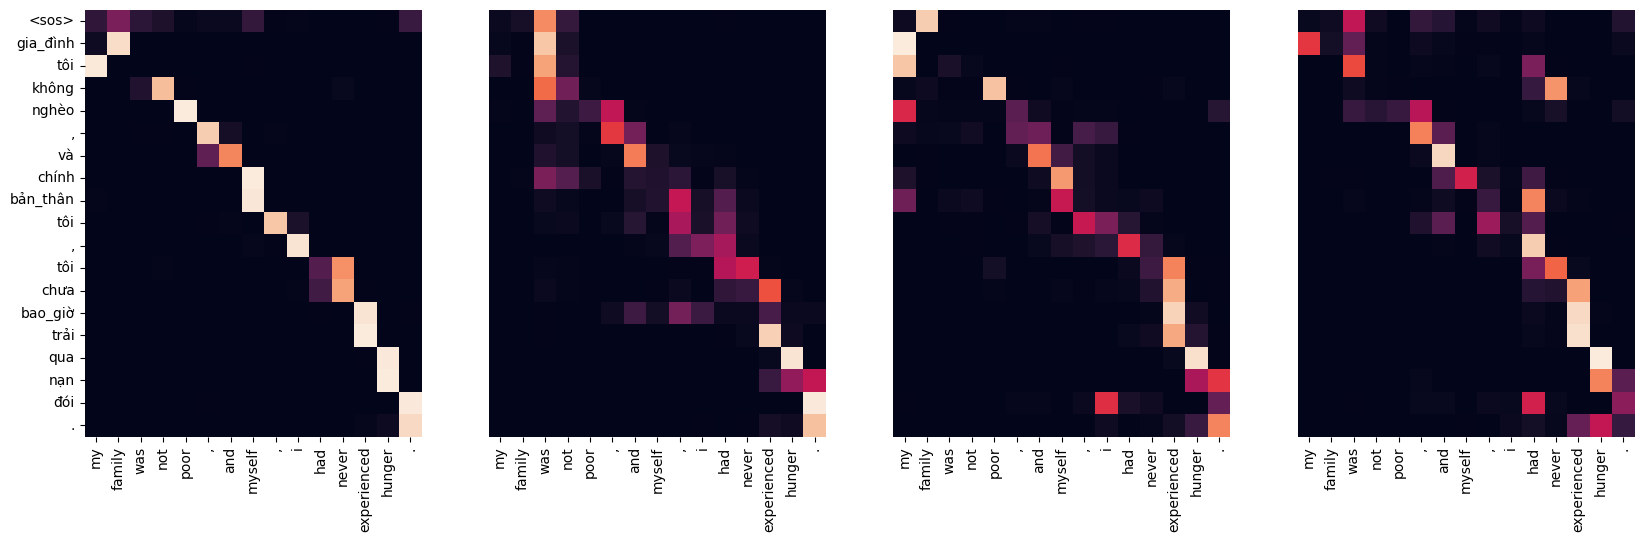

Decoder Self Layer 4


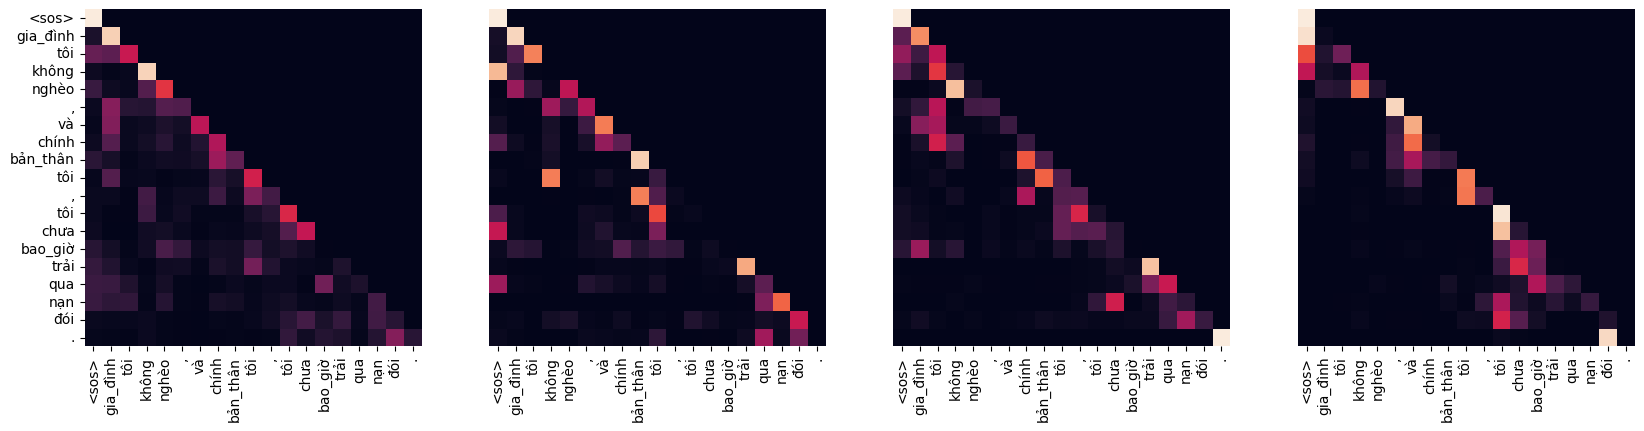

Decoder Src Layer 4


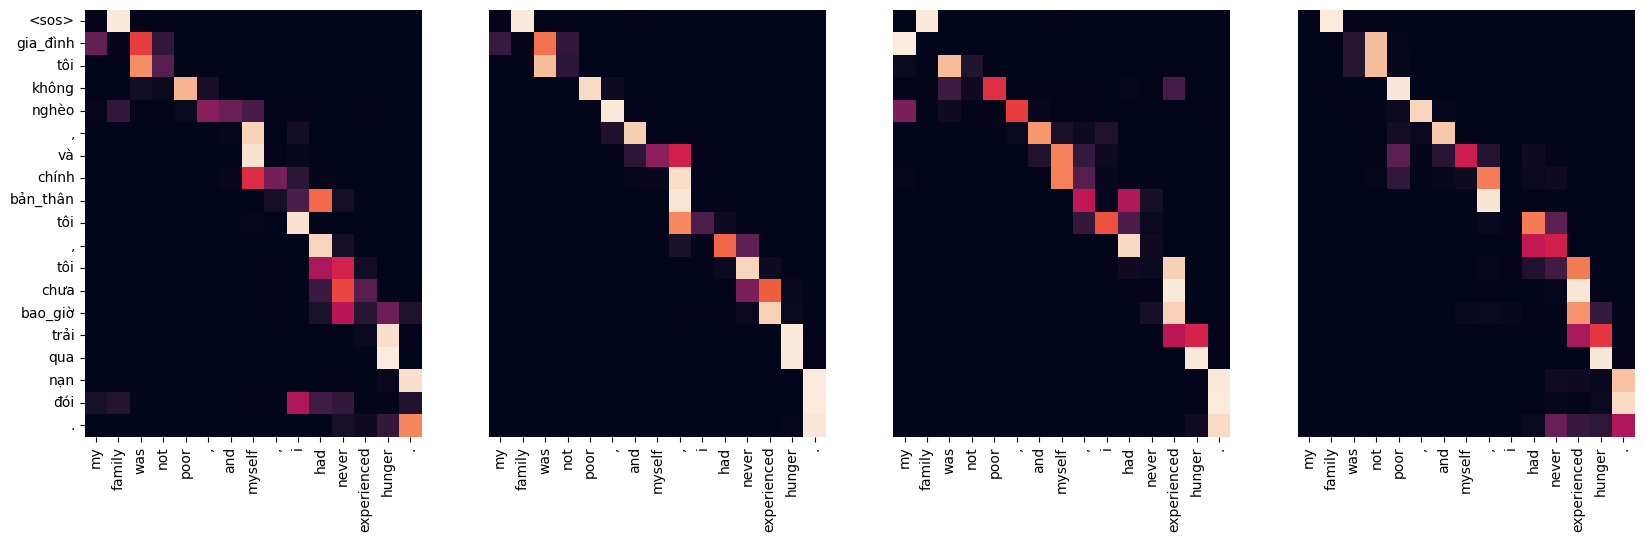

Decoder Self Layer 6


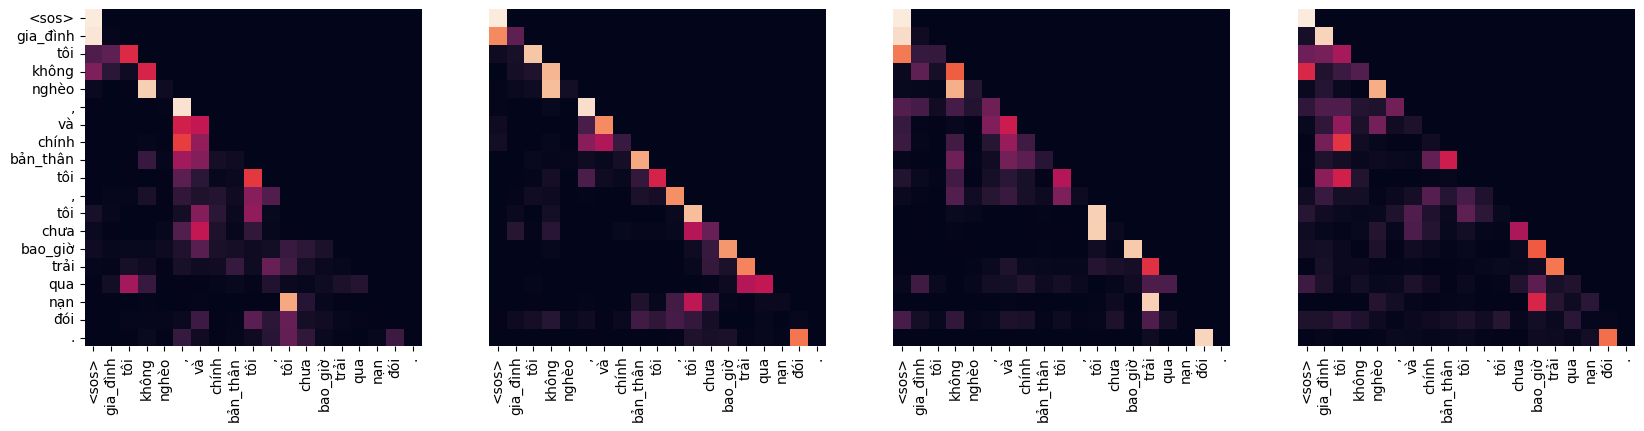

Decoder Src Layer 6


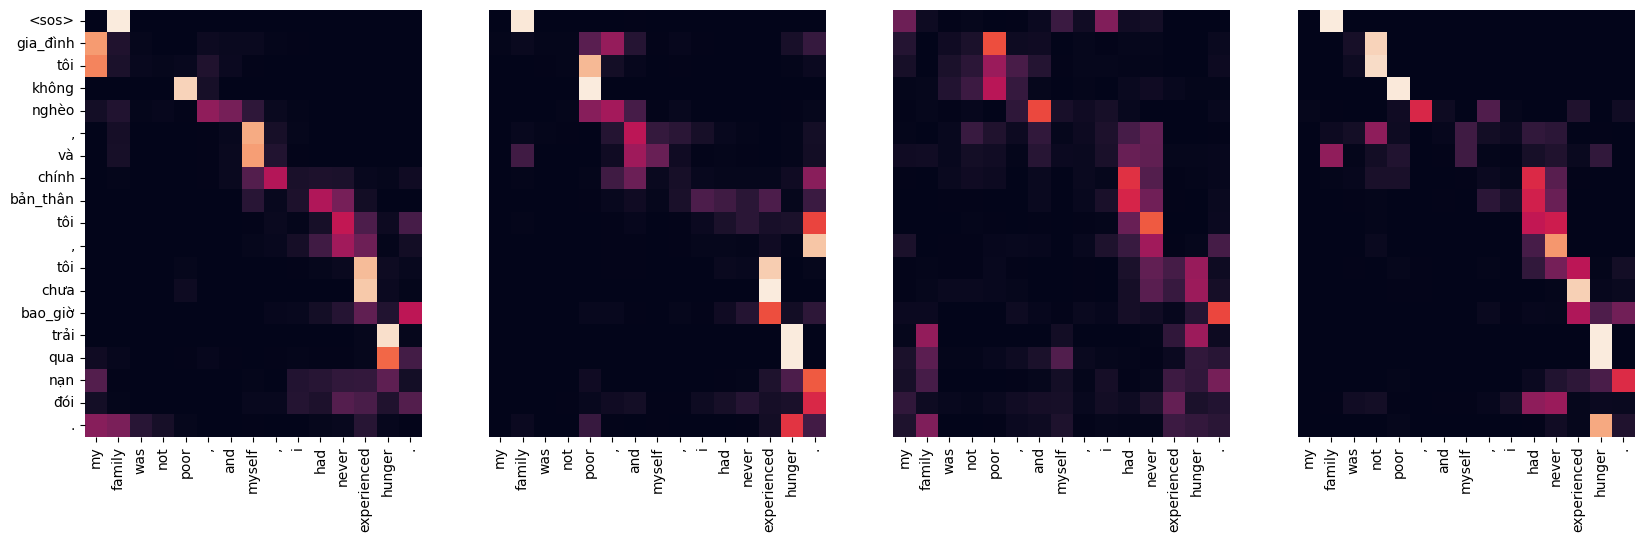

In [91]:
trg_sent = ['<sos>'] + TRG.preprocess(trans_sent)

for layer in range(1, 6, 2):
    fig, axs = plt.subplots(1,4, figsize=(20, 10))
    print("Decoder Self Layer", layer+1)
    for h in range(4):
        draw(model.decoder.layers[layer].attn_1.attn[0, h].data[:len(trg_sent), :len(trg_sent)].cpu(),
            trg_sent, trg_sent if h ==0 else [], ax=axs[h])
    plt.show()
    print("Decoder Src Layer", layer+1)
    fig, axs = plt.subplots(1,4, figsize=(20, 10))
    for h in range(4):
        draw(model.decoder.layers[layer].attn_2.attn[0, h].data[:len(trg_sent), :len(sent)].cpu(),
            sent, trg_sent if h ==0 else [], ax=axs[h])
    plt.show()